<div class="alert alert-block alert-info">
⚠️ This notebook uses the ipython kernel defined in `environments/sym101py_env.yaml`. Please install using `mamba/conda env create -f environments/sym101py_env.yaml` and select the kernel `sym101py_env` before running the notebook.
</div>

In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

from matplotlib import rcParams
# Type 2/TrueType fonts
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42
# Arial font
rcParams['font.sans-serif'] = "Arial"
rcParams['font.family'] = "sans-serif"

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']
cell_line_colors = config['cell_line_colors']

In [2]:
# Load Data
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]
df['essential'] = annotate_essentiality(df.Gene)
df.head()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-04-01-TP2,sym-04-01-TP4,sym-04-01-TP4-TMP,sym-04-02-TP2,sym-04-02-TP4,sym-04-02-TP4-TMP,sym-04-02-TP5,sym-05-01-TP4,sym-05-02-TP4,essential
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,130,171,100,135,143,169,191,147,132,unknown
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,176,221,178,231,193,232,249,251,204,unknown
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,121,149,101,126,116,123,183,125,107,unknown
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,75,101,85,114,77,158,160,141,91,unknown
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,162,185,137,166,186,216,223,165,160,unknown


In [3]:
# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc.replace(0, np.nan))

In [4]:
# Export Source Data
df['mean_l2fc'] = l2fc.mean(axis=1)
# Gene-level annotation
biotype = df.sort_values(['transcript_biotype', 'essential', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]
essential = df.loc[biotype.index, 'essential']
row_order = biotype.index
# Sample-level annotation
cell_line = pd.Series({x: int(x.split('-')[1]) if 'pool' not in x else 'pool' for x in sample_names}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})
treatment = pd.Series({x: 'TMP' if 'TMP' in x else 'None' for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index
data = l2fc.loc[:, col_order].loc[row_order]
# Merge
data.index = pd.MultiIndex.from_arrays([data.index, biotype.loc[data.index], essential.loc[data.index]], names=['sgRNA', 'biotype', 'essential'])
data.columns = pd.MultiIndex.from_arrays([cell_line.loc[data.columns], replicate.loc[data.columns], time_point.loc[data.columns], treatment.loc[data.columns]], names=['cell_line', 'replicate', 'time_point', 'treatment'])
data.to_csv("../results/heatmap/Fig1c_source_data.csv")
data.to_csv("../results/source_tables/Fig1c_source_data.csv")

In [5]:
def plot_heatmap(df, l2fc, 
                 only_last_TP=False,
                 figsize=(15, 10),
                 sort_rows_by=['transcript_biotype', 'essential', 'mean_l2fc'],
                 col_sort_idx=[0, 2, 1],  # line, replicate, time
                 ):
    # Prepare annotation
    df['mean_l2fc'] = l2fc.mean(axis=1)

    # Gene-level annotation
    biotype = df.sort_values(sort_rows_by).transcript_biotype
    biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]
    essential = df.loc[biotype.index, 'essential']
    row_order = biotype.index

    # Sample-level annotation
    cell_line = pd.Series({x: int(x.split('-')[1]) if 'pool' not in x else 'pool' for x in sample_names}).replace(cell_line_dict)
    replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
    time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})
    treatment = pd.Series({x: 'TMP' if 'TMP' in x else 'None' for x in sample_names})
    col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values(col_sort_idx).index
    
    # Column annotation
    if only_last_TP:
        col_order = [x for x in col_order if 'pool' in x or 'TP6' in x]  # only last time point and pools
        top_ha = pch.HeatmapAnnotation(
            cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, colors=cell_line_colors),
            replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
            verbose=0, axis=1, plot_legend=False
        )
    else:
        from matplotlib.colors import LinearSegmentedColormap
        cmap = sns.color_palette('Blues', as_cmap=True)
        colors = [cmap(x) for x in np.linspace(0.2, 0.9, 7)] + [(1, 1, 1, 1)]  # white for TP0
        time_cmap = LinearSegmentedColormap.from_list("gradual_colormap", colors, N=7)
        top_ha = pch.HeatmapAnnotation(
            cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, colors=cell_line_colors),
            time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap=time_cmap),
            replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
            treatment=pch.anno_simple(treatment.loc[col_order], add_text=False, colors={'TMP': 'tab:orange', 'None': 'lightgrey'}),
            verbose=0, axis=1, plot_legend=False
        )
    
    # Apply select and reorder to plot data
    data = l2fc.loc[:, col_order].loc[row_order]

    # Row annotation
    left_ha = pch.HeatmapAnnotation(
        label=pch.anno_label(biotype, merge=True, cmap='Pastel2'),
        biotype=pch.anno_simple(biotype, legend=True, height=7, add_text=True, cmap='Pastel2'),
        essentiality=pch.anno_simple(essential, legend=True, height=7, add_text=False, colors={'essential': 'tab:red', 'non-essential': 'tab:blue', 'unknown': 'lightgrey'}),
        verbose=0, axis=0, plot_legend=True
    )

    # Plot
    pl.figure(figsize=figsize)
    cm = pch.ClusterMapPlotter(
        data=data, left_annotation=left_ha, top_annotation=top_ha,
        row_cluster=False, col_cluster=False,
        row_split=biotype, col_split=cell_line.loc[col_order],
        col_split_gap=2,row_split_gap=1,
        label='beta', row_dendrogram=False, col_dendrogram=False,
        legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
        legend_kws=dict(label='L2FC'),
        xlabel="Samples", ylabel='Guides', legend_hpad=0,
        verbose=0
    )
    pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1', y=0.92)
    return cm

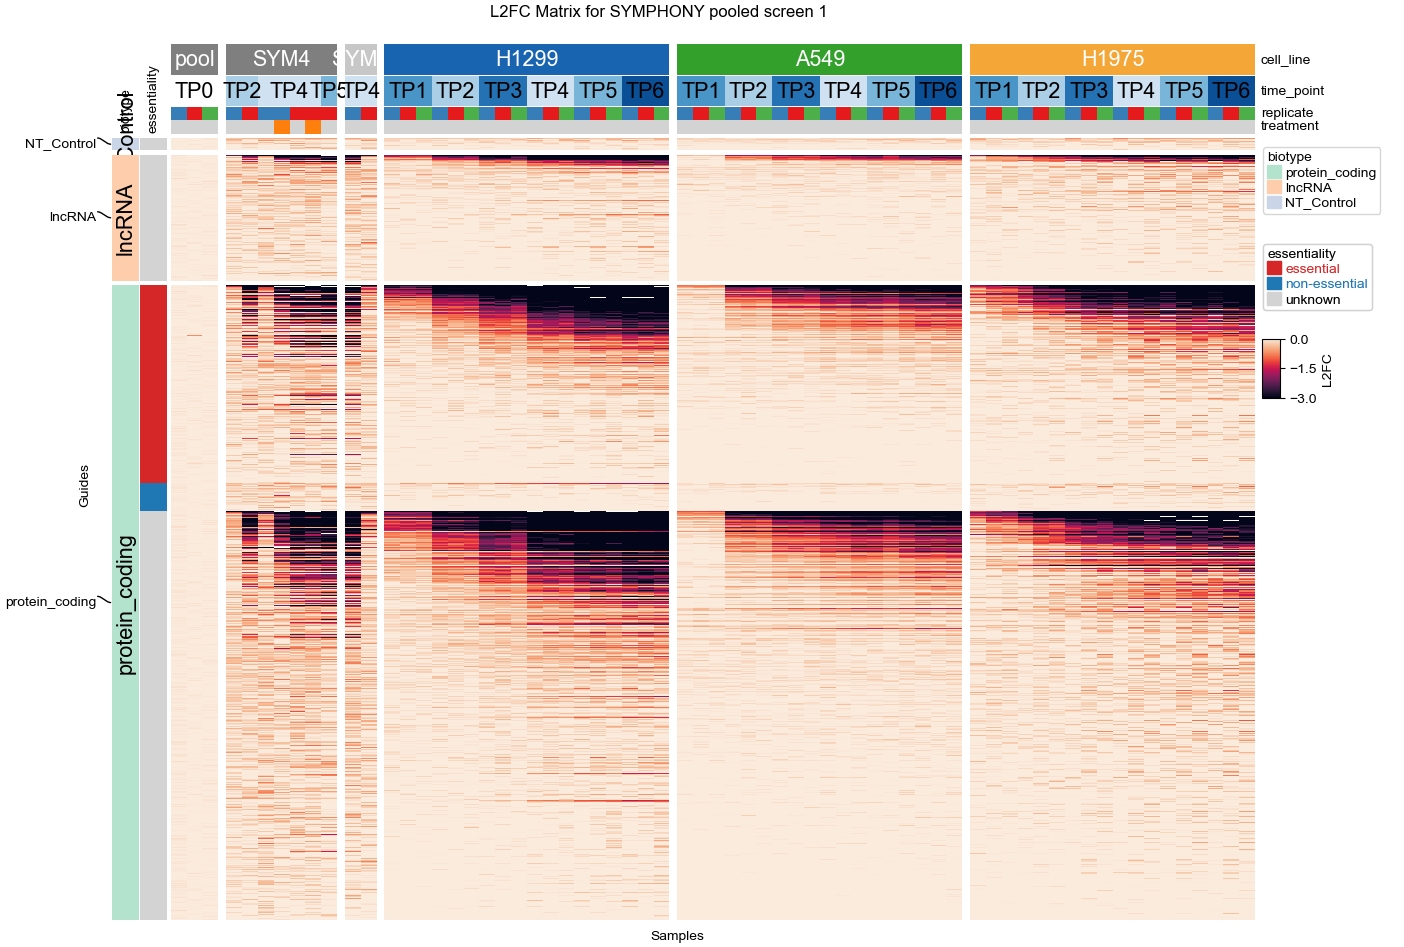

In [6]:
cm = plot_heatmap(df, l2fc)
Path('../results/heatmap').mkdir(parents=True, exist_ok=True)
pl.savefig('../results/heatmap/count_matrix_l2fc_heatmap_simple_plus.png', dpi=300)
pl.savefig('../results/heatmap/count_matrix_l2fc_heatmap_simple_plus.pdf', dpi=300, bbox_inches='tight')
pl.show()

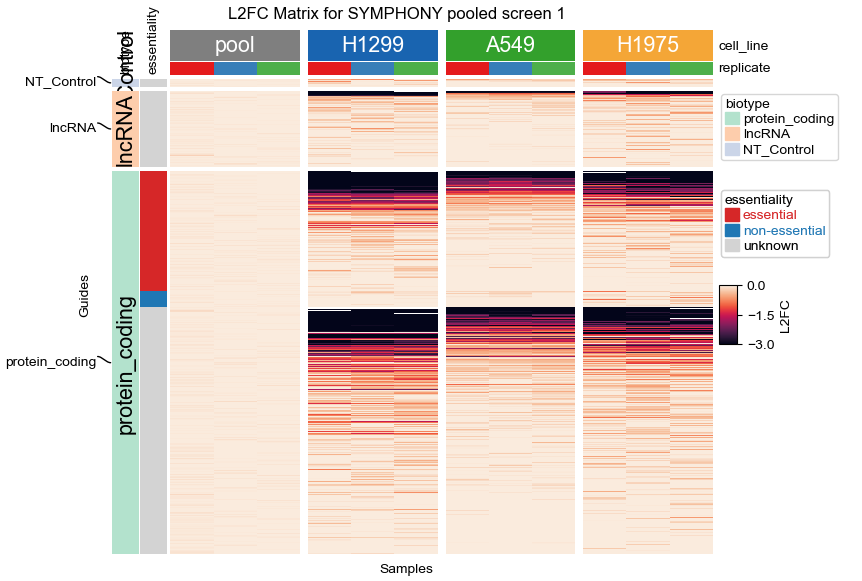

In [8]:
# Only last TP, smaller heatmap
cm = plot_heatmap(df, l2fc, only_last_TP=True, figsize=(8, 6))
Path('../results/heatmap').mkdir(parents=True, exist_ok=True)
pl.savefig('../results/heatmap/count_matrix_l2fc_heatmap_simple_plus_plain.png', dpi=300)
pl.savefig('../results/heatmap/count_matrix_l2fc_heatmap_simple_plus_plain.pdf', dpi=300, bbox_inches='tight')
pl.show()